In [1]:
pip install requests lxml cvxopt riskfolio-lib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# trabajo con tablas y visualizacion
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas import read_csv, set_option
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from datetime import date

# clustering
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from sklearn.metrics import adjusted_mutual_info_score
from sklearn import cluster, covariance, manifold

# optimizacion media-varianza
import cvxopt as opt # installar en terminal (pip instal cvxopt)
from cvxopt import blas, solvers

In [12]:
from pandas import read_csv
# Cargar datos
raw_data = read_csv('inputs/sp500_closes.csv', index_col=0)

import warnings
warnings.filterwarnings('ignore')

dataset = raw_data.copy()
dataset = dataset.sort_index(ascending=True)
dataset.head()

,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,63.522758,40.304173,68.773132,NaN,50.506081,27.988113,135.558258,177.699997,77.602280,31.407618,...,25.617334,150.072815,37.154202,58.580421,61.646584,36.169998,70.179703,112.586151,103.709999,66.814163
2018-01-03,65.139015,40.297161,69.849365,NaN,50.617764,28.013470,136.183838,181.039993,78.564980,31.164762,...,25.842295,148.446991,36.905533,59.730946,62.398289,37.310001,70.119492,113.366631,105.769997,67.121361
2018-01-04,64.650398,40.484329,69.451027,NaN,50.531853,28.118069,137.796387,183.220001,78.479034,31.689665,...,25.631851,149.250717,36.617989,59.813633,62.814873,38.099998,70.833328,113.203247,107.860001,67.521660
2018-01-05,65.684044,40.945278,70.660011,NaN,50.677914,28.007132,138.933105,185.339996,78.797096,31.478130,...,25.595564,150.246353,36.361534,59.765415,62.697132,41.139999,71.246147,114.328606,109.540001,68.294357
2018-01-08,65.824989,40.793171,69.527901,NaN,50.531853,28.010302,140.043335,185.039993,78.934624,31.407618,...,25.762468,148.245987,36.633530,60.034077,62.923531,40.759998,71.366570,114.546387,110.629997,69.113594


In [13]:
# Eliminar columnas con >30% de missings
proporcion_missing = dataset.isnull().mean()

cond = proporcion_missing > 0.3
drop_list = list(proporcion_missing.loc[cond].index)

print(f'Columnas a eliminar por tener >30% de missings: {drop_list}')

dataset = dataset.drop(labels=drop_list, axis=1)

# Imputar el resto con 'forward fill'
dataset = dataset.fillna(method='ffill')

dataset.head()

Columnas a eliminar por tener >30% de missings: ['ABNB', 'APP', 'CARR', 'CEG', 'COIN', 'CRWD', 'CTVA', 'DASH', 'DDOG', 'DOW', 'EXE', 'FOX', 'FOXA', 'GEHC', 'GEV', 'HOOD', 'KVUE', 'MRNA', 'OTIS', 'PLTR', 'Q', 'SNDK', 'SOLV', 'UBER', 'VLTO', 'VRT']


,A,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,ADM,ADP,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,63.522758,40.304173,68.773132,50.506081,27.988113,135.558258,177.699997,77.602280,31.407618,97.140251,...,25.617334,150.072815,37.154202,58.580421,61.646584,36.169998,70.179703,112.586151,103.709999,66.814163
2018-01-03,65.139015,40.297161,69.849365,50.617764,28.013470,136.183838,181.039993,78.564980,31.164762,98.195488,...,25.842295,148.446991,36.905533,59.730946,62.398289,37.310001,70.119492,113.366631,105.769997,67.121361
2018-01-04,64.650398,40.484329,69.451027,50.531853,28.118069,137.796387,183.220001,78.479034,31.689665,99.133469,...,25.631851,149.250717,36.617989,59.813633,62.814873,38.099998,70.833328,113.203247,107.860001,67.521660
2018-01-05,65.684044,40.945278,70.660011,50.677914,28.007132,138.933105,185.339996,78.797096,31.478130,99.074860,...,25.595564,150.246353,36.361534,59.765415,62.697132,41.139999,71.246147,114.328606,109.540001,68.294357
2018-01-08,65.824989,40.793171,69.527901,50.531853,28.010302,140.043335,185.039993,78.934624,31.407618,98.773361,...,25.762468,148.245987,36.633530,60.034077,62.923531,40.759998,71.366570,114.546387,110.629997,69.113594


In [18]:
# Separar 80/20
X = dataset.copy()
n_filas = len(X)
train_len = int(n_filas*.8)
X_train = X.head(train_len)
X_test = X.tail(n_filas-train_len)

# Calcular retornos
returns = X_train.pct_change().dropna()
returns_test = X_test.pct_change().dropna()

print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)

print("Primeras filas de returns (train):")
returns.head()

Shape X_train: (358, 477)
Shape X_test: (90, 477)
Primeras filas de returns (train):


,A,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,ADM,ADP,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-03,0.025444,-0.000174,0.015649,0.002211,0.000906,0.004615,0.018796,0.012406,-0.007732,0.010863,...,0.008782,-0.010834,-0.006693,0.019640,0.012194,0.031518,-0.000858,0.006932,0.019863,0.004598
2018-01-04,-0.007501,0.004645,-0.005703,-0.001697,0.003734,0.011841,0.012042,-0.001094,0.016843,0.009552,...,-0.008143,0.005414,-0.007791,0.001384,0.006676,0.021174,0.010180,-0.001441,0.019760,0.005964
2018-01-05,0.015988,0.011386,0.017408,0.002890,-0.003945,0.008249,0.011571,0.004053,-0.006675,-0.000591,...,-0.001416,0.006671,-0.007004,-0.000806,-0.001874,0.079790,0.005828,0.009941,0.015576,0.011444
2018-01-08,0.002146,-0.003715,-0.016022,-0.002882,0.000113,0.007991,-0.001619,0.001745,-0.002240,-0.003043,...,0.006521,-0.013314,0.007480,0.004495,0.003611,-0.009237,0.001690,0.001905,0.009951,0.011996
2018-01-09,0.024554,-0.000114,0.007539,0.001700,-0.012900,0.003335,0.008971,-0.002069,0.003243,0.006953,...,-0.006760,0.006777,-0.011667,-0.004246,0.000288,0.002944,-0.002651,-0.016083,0.030643,0.011719


In [19]:
print("Primeras filas de returns_test (test):")
returns_test.head()

Primeras filas de returns_test (test):


,A,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,ADM,ADP,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2019-06-07,0.005205,0.026617,0.004671,0.008116,0.001686,0.013969,0.012227,0.007202,-0.003274,0.015946,...,0.029870,0.009456,-0.006187,0.003634,0.005180,0.040900,0.005995,0.003491,0.036367,0.010745
2019-06-10,0.011076,0.012779,-0.006199,0.006564,-0.006173,0.008310,0.007837,0.058199,0.012127,0.004613,...,0.013451,0.050892,-0.002861,0.004425,0.010307,0.027900,-0.003851,0.008117,0.032595,0.001454
2019-06-11,-0.002846,0.011580,0.015854,-0.001846,-0.011858,-0.005801,-0.015517,-0.012952,0.002746,-0.015385,...,0.014932,0.012685,-0.009619,-0.000935,-0.004727,-0.002700,-0.009940,-0.010106,-0.012544,-0.000544
2019-06-12,0.002854,-0.003182,0.005117,0.010232,0.001143,0.006653,0.003080,-0.007607,0.013692,0.000666,...,0.024111,-0.028862,0.014142,-0.010823,0.002625,0.003990,0.012736,0.001743,0.008122,0.011619
2019-06-13,0.000142,-0.000206,0.004836,0.004149,0.000000,0.001950,-0.001951,0.013509,0.007122,0.000122,...,0.008779,0.021527,0.005667,0.008780,0.010971,0.024411,0.000367,-0.007457,0.001911,-0.012653


In [22]:
from scipy.cluster.hierarchy import linkage

# Calcular matriz de correlación
correlations = returns.corr()

# Función para convertir correlación en distancia
def correlDist(corr_matrix):
    dist = ((1 - corr_matrix) / 2) ** 0.5
    return dist

# Calcular distancias
dist = correlDist(correlations)

# Calcular los enlaces del cluster jerárquico
# 'ward' es el método que minimiza la varianza
link = linkage(y=dist, method='ward')

print("Matriz de correlación (primeras filas):")
print(correlations.head())

print("\nMatriz de distancias (primeras filas):")
print(dist.head())

print("\nPrimeros 5 enlaces del cluster jerárquico:")
print(link[:5])

Matriz de correlación (primeras filas):
             A      AAPL      ABBV       ABT      ACGL       ACN      ADBE  \
A     1.000000  0.435447  0.375088  0.602592  0.357258  0.568328  0.559852   
AAPL  0.435447  1.000000  0.302924  0.527199  0.335332  0.597456  0.632119   
ABBV  0.375088  0.302924  1.000000  0.494995  0.287078  0.455927  0.379012   
ABT   0.602592  0.527199  0.494995  1.000000  0.442048  0.621366  0.618254   
ACGL  0.357258  0.335332  0.287078  0.442048  1.000000  0.434192  0.354722   

           ADI       ADM       ADP  ...        WY      WYNN       XEL  \
A     0.523367  0.353608  0.541357  ...  0.317969  0.300742  0.076697   
AAPL  0.572806  0.370275  0.568583  ...  0.334722  0.362014  0.024078   
ABBV  0.325508  0.299913  0.373383  ...  0.194501  0.179093  0.127794   
ABT   0.526766  0.380504  0.588597  ...  0.369379  0.303193  0.168820   
ACGL  0.400696  0.371816  0.466250  ...  0.274824  0.261120  0.133578   

           XOM       XYL       XYZ       YUM       Z

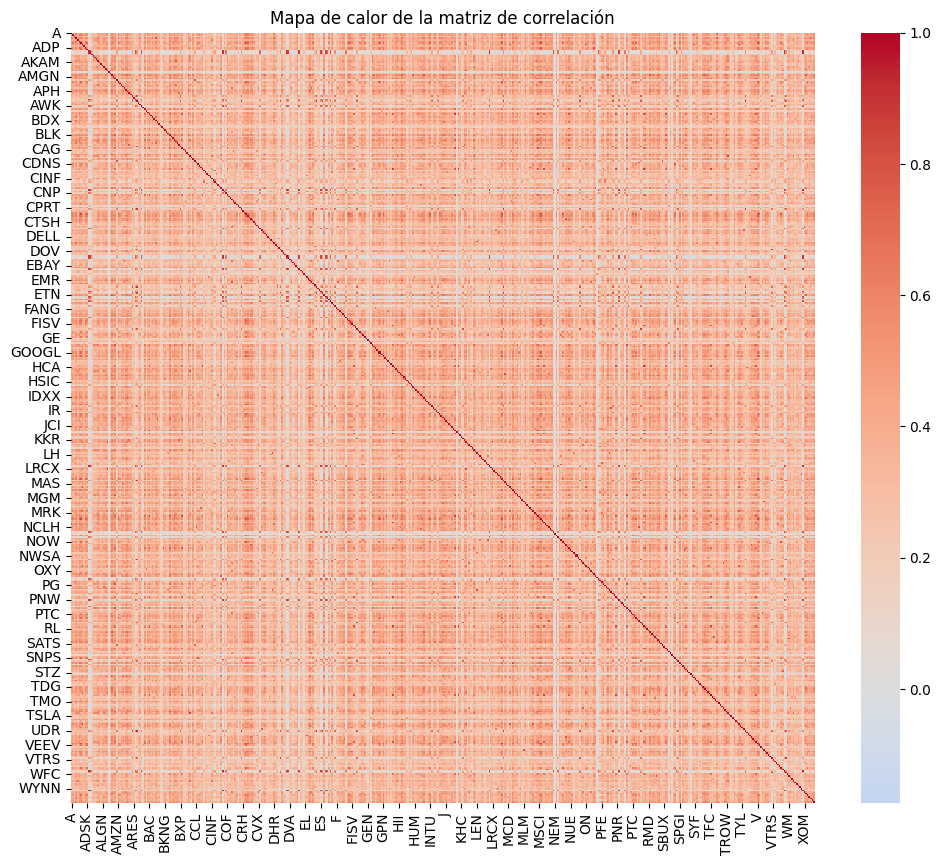

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))
sns.heatmap(correlations, cmap='coolwarm', center=0)
plt.title('Mapa de calor de la matriz de correlación')
plt.show()

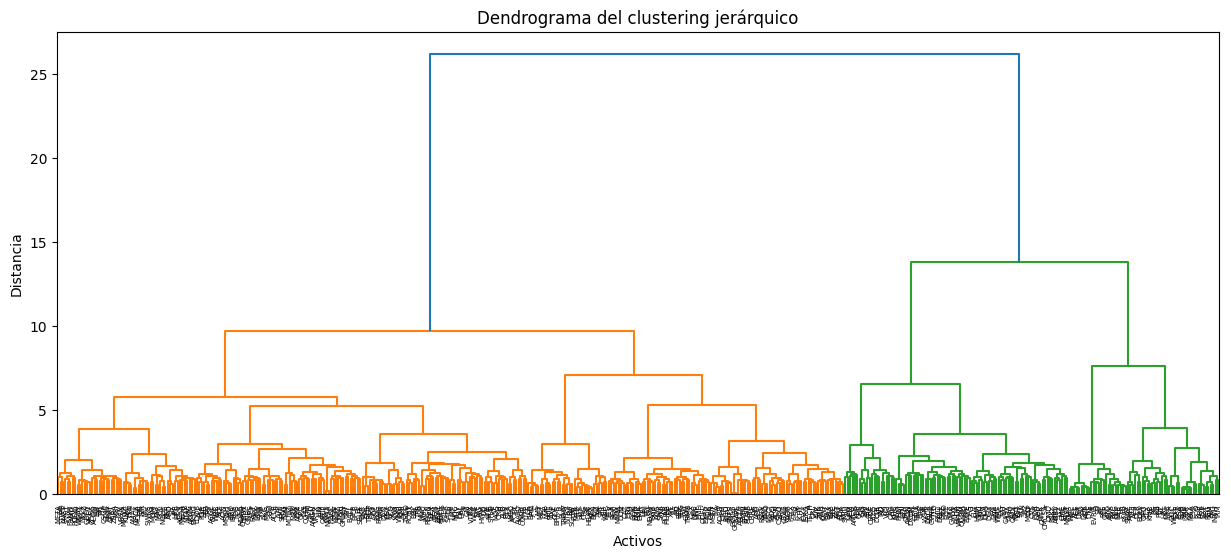

In [25]:
from scipy.cluster.hierarchy import dendrogram

plt.figure(figsize=(15, 6))
dendrogram(link, labels=correlations.columns, leaf_rotation=90)
plt.title('Dendrograma del clustering jerárquico')
plt.xlabel('Activos')
plt.ylabel('Distancia')
plt.show()

You must convert self.cov to a positive definite matrix
Pesos de los Portafolios (MVP vs HRP):
               MVP       HRP
A     1.740989e-10  0.001010
AAPL  2.349357e-10  0.001055
ABBV  1.791020e-10  0.001700
ABT   1.724928e-10  0.001661
ACGL  9.962048e-10  0.003769
ACN   2.720312e-10  0.001612
ADBE  1.301603e-10  0.000558
ADI   1.820929e-10  0.000912
ADM   1.709900e-09  0.006399
ADP   1.686897e-10  0.001680
ADSK  1.016472e-10  0.000477
AEE   7.101105e-10  0.002616
AEP   8.154362e-09  0.005538
AES   2.762077e-10  0.004376
AFL   2.584073e-09  0.002635
AIG   6.165439e-03  0.002268
AIZ   4.649031e-10  0.002988
AJG   5.102969e-10  0.004622
AKAM  1.527476e-10  0.001387
ALB   1.826177e-10  0.000916
ALGN  6.507808e-11  0.000552
ALL   9.746408e-10  0.003613
ALLE  2.830333e-10  0.001777
AMAT  8.955870e-11  0.000510
AMCR  1.381956e-01  0.009822
AMD   6.225965e-11  0.000284
AME   1.825157e-10  0.001285
AMGN  1.663681e-10  0.003293
AMP   1.322728e-10  0.000981
AMT   4.453032e-10  0.003791
AMZN  

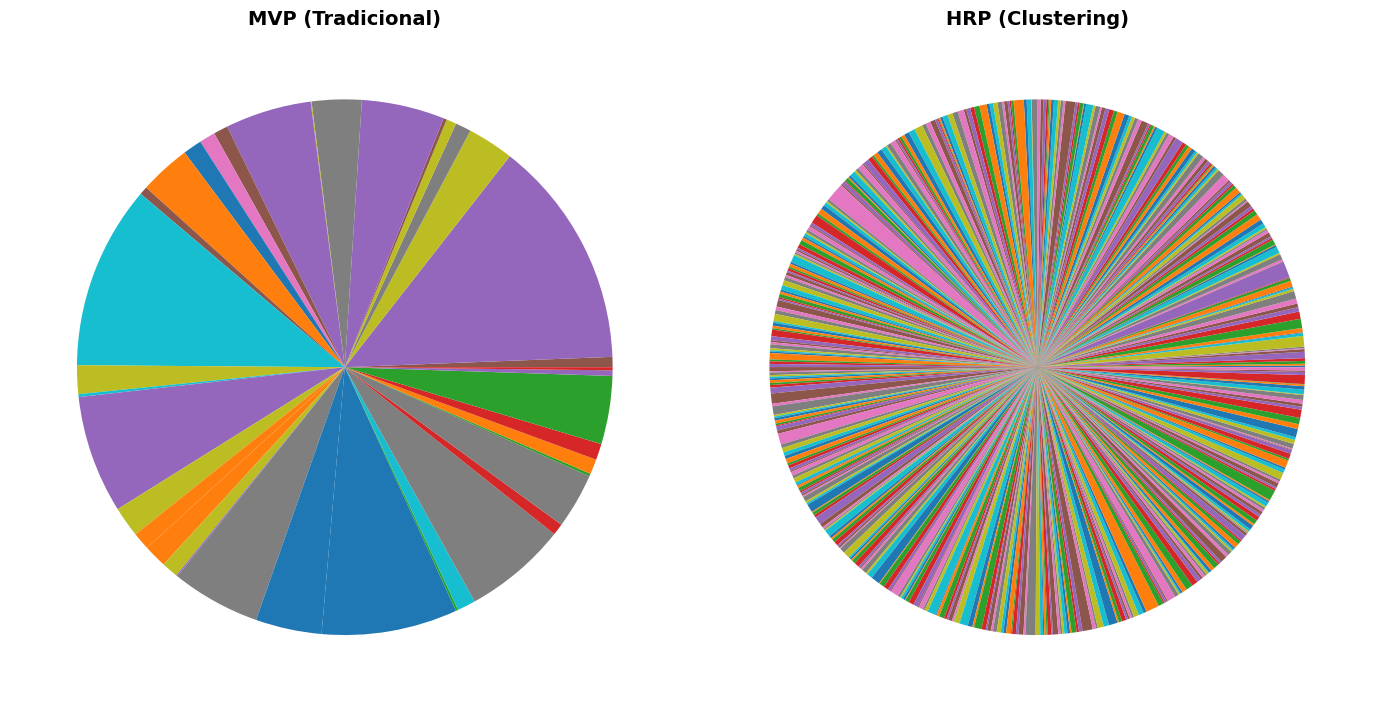

In [26]:
# Importar las librerías necesarias
import riskfolio as pf
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Portafolio HRP (Clusterizado) ---
port_hrp = pf.HCPortfolio(returns=returns)

weights_hrp = port_hrp.optimization(model='HRP',
                                    codependence='pearson',
                                    rm='MV', # Risk Measure = Variance
                                    rf=0, 
                                    linkage='ward', 
                                    leaf_order=True)

# --- 2. Portafolio MVP (Tradicional) ---
port_mvp = pf.Portfolio(returns=returns)

port_mvp.assets_stats(method_mu='hist', method_cov='hist')

# Ahora podemos optimizar para el modelo 'Classic'
weights_mvp = port_mvp.optimization(model='Classic', 
                                    rm='MV', 
                                    obj='MinRisk', 
                                    rf=0, 
                                    l=0)

# --- 3. Unir los portafolios en la tabla (como en la guía) ---
portfolios = pd.concat([weights_mvp, weights_hrp], axis=1)
portfolios.columns = ['MVP', 'HRP'] # Nombramos las columnas

print("Pesos de los Portafolios (MVP vs HRP):")
print(portfolios.head(50))

# --- 4. Graficar los Gráficos de Torta (Pie Charts) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# Gráfico 1: MVP (Mínima Varianza)
ax1.pie(portfolios.iloc[:, 0])
ax1.set_title('MVP (Tradicional)', fontsize=14, fontweight='bold')

# Gráfico 2: HRP (Con Clustering)
ax2.pie(portfolios.iloc[:, 1])
ax2.set_title('HRP (Clustering)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

Mostrando gráficos de rendimiento...


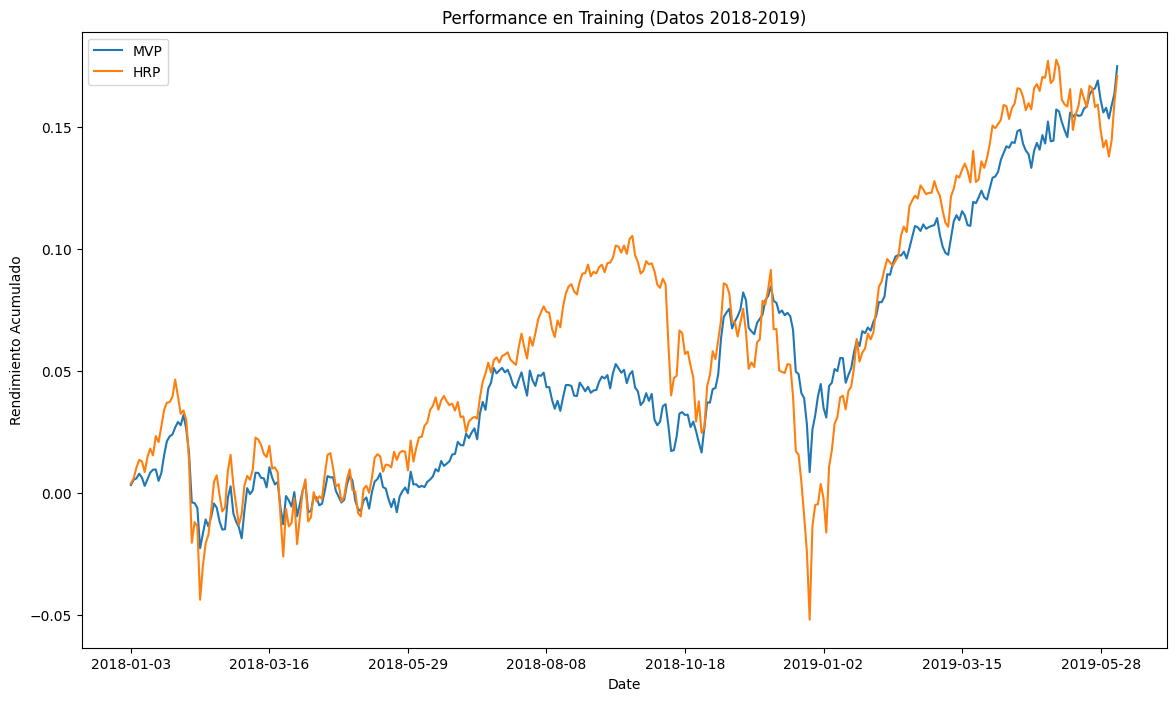

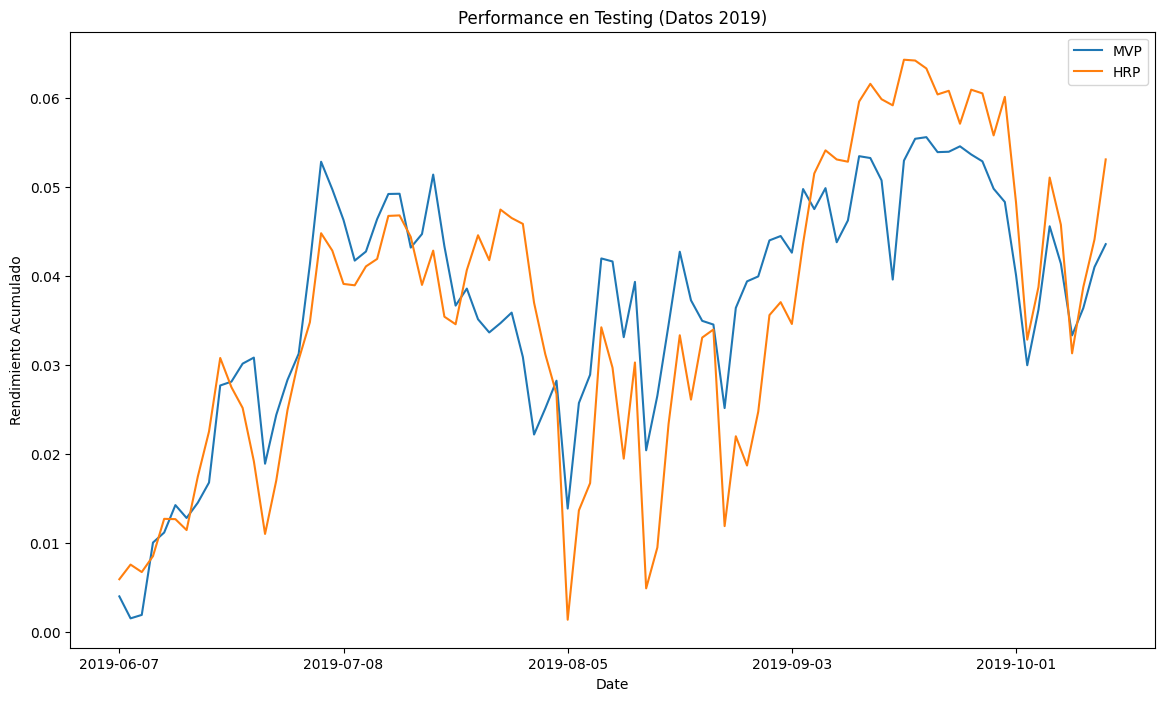

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Calcular el rendimiento en los datos de ENTRENAMIENTO ---
# (Multiplicamos los retornos de train por los pesos que encontramos)
training_results = pd.DataFrame(
    np.dot(returns, np.array(portfolios)), 
    columns=['MVP', 'HRP'], 
    index=returns.index
)

# --- 2. Calcular el rendimiento en los datos de PRUEBA ---
# (Multiplicamos los retornos de test por los MISMOS pesos)
testing_results = pd.DataFrame(
    np.dot(returns_test, np.array(portfolios)), 
    columns=['MVP', 'HRP'], 
    index=returns_test.index
)

# --- 3. Graficar los resultados ---
# (Usamos .cumsum() para ver el crecimiento acumulado)
print("Mostrando gráficos de rendimiento...")

# Gráfico 1: Performance en Training
(training_results.cumsum()).plot(figsize=(14, 8), title="Performance en Training (Datos 2018-2019)")
plt.ylabel("Rendimiento Acumulado")
plt.show()

# Gráfico 2: Performance en Testing (La prueba de fuego)
(testing_results.cumsum()).plot(figsize=(14, 8), title="Performance en Testing (Datos 2019)")
plt.ylabel("Rendimiento Acumulado")
plt.show()

In [29]:
import numpy as np
import pandas as pd

# --- 1. Calcular las métricas en los datos de PRUEBA ---

# Volatilidad Anualizada
stddev_oos = testing_results.std() * np.sqrt(252)

# Rentabilidad Anualizada (Usando la media aritmética, que es estable)
return_oos = testing_results.mean() * 252

# Sharpe Ratio Anualizado
sharp_ratio_oos = return_oos / stddev_oos

# --- 2. Mostrar los resultados en una tabla ---
# (La guía usa 'stdev_oos' y 'sharp_ratio_oos')
Results_oos = pd.DataFrame(dict(
    stdev_oos=stddev_oos, 
    sharp_ratio_oos=sharp_ratio_oos
))

print("--- VEREDICTO FINAL (Datos de Prueba) ---")
print(Results_oos)

--- VEREDICTO FINAL (Datos de Prueba) ---
     stdev_oos  sharp_ratio_oos
MVP   0.098554         1.251318
HRP   0.123894         1.213153


--- VEREDICTO FINAL (Datos de Prueba) ---
     stdev_oos  sharp_ratio_oos
MVP   0.098554         1.251318
HRP   0.123894         1.213153

Generando gráfico del veredicto...


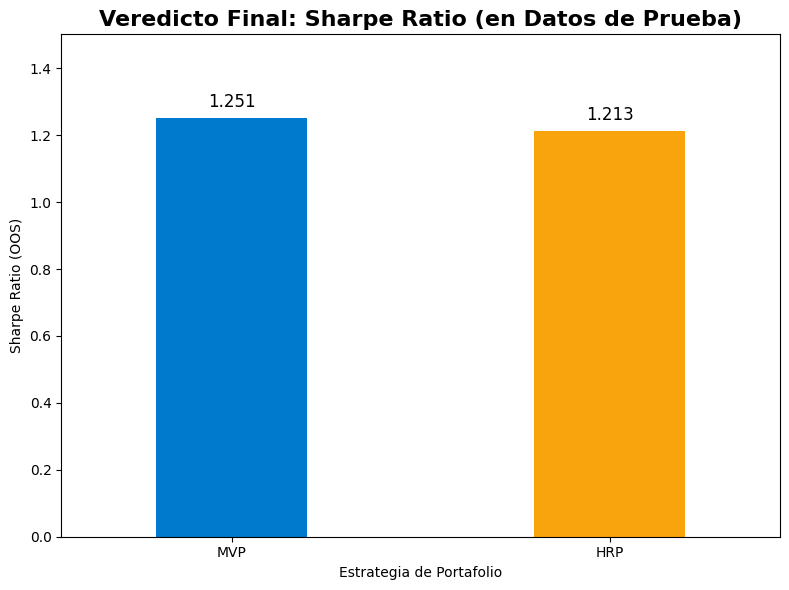

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Calcular las métricas (lo ya hecho) ---
# Asumimos que 'testing_results' ya existe
stddev_oos = testing_results.std() * np.sqrt(252)
return_oos = testing_results.mean() * 252
sharp_ratio_oos = return_oos / stddev_oos

Results_oos = pd.DataFrame(dict(
    stdev_oos=stddev_oos, 
    sharp_ratio_oos=sharp_ratio_oos
))

print("--- VEREDICTO FINAL (Datos de Prueba) ---")
print(Results_oos)

# --- 2. ¡NUEVO! Generar el Gráfico de Barras ---
print("\nGenerando gráfico del veredicto...")

# Extraemos solo los Sharpe Ratios
final_sharpe_ratios = Results_oos['sharp_ratio_oos']

fig, ax = plt.subplots(figsize=(8, 6))

# Crear las barras (azul para MVP, naranja para HRP)
final_sharpe_ratios.plot(
    kind='bar', 
    ax=ax, 
    color=['#007ACC', '#FAA40D'], # Colores estándar (Azul, Naranja)
    width=0.4,  # Ancho de las barras
    rot=0       # Rotación de las etiquetas del eje X
)

# Añadir etiquetas de datos (los números) encima de las barras
ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=12, padding=5)

# Configurar el gráfico
ax.set_title('Veredicto Final: Sharpe Ratio (en Datos de Prueba)', fontsize=16, fontweight='bold')
ax.set_ylabel('Sharpe Ratio (OOS)')
ax.set_xlabel('Estrategia de Portafolio')
ax.set_ylim(0, final_sharpe_ratios.max() * 1.2) # Dar espacio arriba

plt.tight_layout()
plt.show()

Generando gráfico de Riesgo (Volatilidad)...


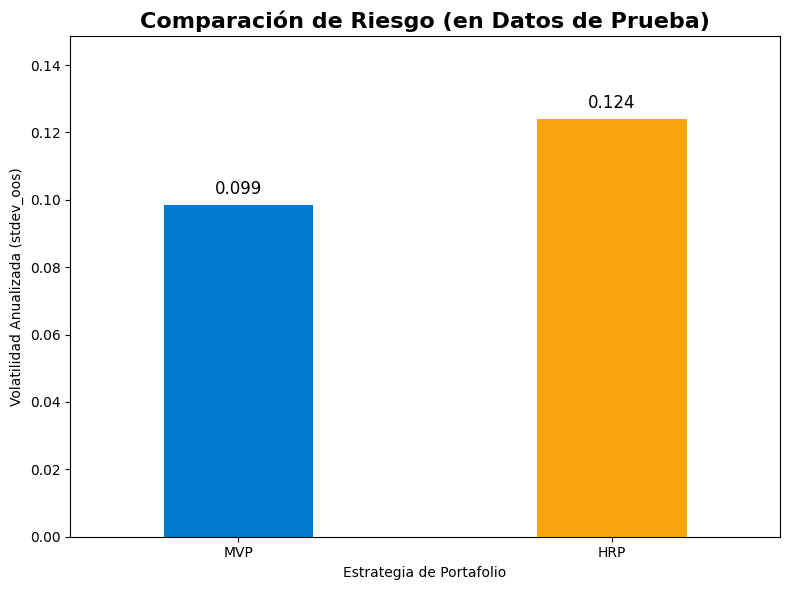

In [31]:
import matplotlib.pyplot as plt

# --- 1. Extraer los datos de RIESGO (Volatilidad) ---
# (Asumimos que el DataFrame 'Results_oos' ya existe)
final_stdev = Results_oos['stdev_oos']

print("Generando gráfico de Riesgo (Volatilidad)...")

# --- 2. Generar el Gráfico de Barras ---
fig, ax = plt.subplots(figsize=(8, 6))

# Crear las barras
final_stdev.plot(
    kind='bar', 
    ax=ax, 
    color=['#007ACC', '#FAA40D'], # Colores (Azul, Naranja)
    width=0.4,
    rot=0
)

# Añadir etiquetas de datos (los números) encima de las barras
ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=12, padding=5)

# Configurar el gráfico
ax.set_title('Comparación de Riesgo (en Datos de Prueba)', fontsize=16, fontweight='bold')
ax.set_ylabel('Volatilidad Anualizada (stdev_oos)')
ax.set_xlabel('Estrategia de Portafolio')
ax.set_ylim(0, final_stdev.max() * 1.2) # Dar espacio arriba

plt.tight_layout()
plt.show()